#American Sign Language Dataset: Konvolucione neuronske mreže

U prethodnom *notebook*-u smo trenirali potpuno povezanu neuronsku mrežu na ASL skupu podataka. Dostigli smo visoku tačnost na trening skupu, ali tačnost na test skupu nije bila zadovoljavajuća. U ovom *notebook*-u ćemo probati da istreniramo CNN na ASL skupu podataka.



## Podaci - učitavanje i priprema (normalizacija, enkodiranje labele)

In [1]:
import tensorflow.keras as keras
import pandas as pd

# Load in our data from CSV files
train_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/CNN vežbe/data/asl_data/sign_mnist_train.csv")
test_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/CNN vežbe/data/asl_data/sign_mnist_valid.csv")

# Separate out our target values
y_train = train_df['label']
y_test = test_df['label']
del train_df['label']
del test_df['label']

# Separate out our image vectors
x_train = train_df.values
x_test = test_df.values

# Turn our scalar targets into binary categories
num_classes = 24
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

# Normalize our image data
x_train = x_train / 255
x_test = x_test / 255

## *Reshape* podataka za CNN

Individualne slike u skupu podataka su u formatu 1D niza od 784 elemenata (vrednosti piksela):

In [2]:
x_train.shape, x_test.shape

((27455, 784), (7172, 784))

CNN tipično primaju sliku (2D) ulaz - na taj način se održava prostorna povezanost (koji pikseli su međusobno blizu).

Zato ćemo *reshape*-ovati slike da budu u originalnom formatu (2D niz 28 x 28). Takođe, imajte u vidu da slika nema samo rezoluciju (28 x 28), već i određeni broj kanala boja. U slučaju ovog skupa podataka, slike su *grayscale*, te imamo samo 1 kanal, tj., slike su formata 28 x 28 x 1.

Ovo znači da, npr. za trening skup od 27455 slika, treba da konvertujemo trenutni shape (27455, 784) u (27455, 28, 28, 1). Metod [`reshape`](https://numpy.org/doc/stable/reference/generated/numpy.reshape.html#numpy.reshape) nam pruža mogućnost da prosledimo -1 za dimenziju koju ne želimo da menjamo, dakle:

In [3]:
x_train = x_train.reshape(-1,28,28,1)
x_test = x_test.reshape(-1,28,28,1)

In [5]:
x_train.shape, x_test.shape

((27455, 28, 28, 1), (7172, 28, 28, 1))

## Podela trening podataka na trening i validacioni skup

In [6]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

## Kreiranje CNN modela

Danas imamo na raspolaganju već mnogo gotovih (treniranih) modela. Primeri takvih kataloga su [TensorFlowHub](https://www.tensorflow.org/hub) i [NGC Catalog](https://catalog.ngc.nvidia.com/models). Ako vaš problem nije jedinstven, što je malo verovatno, verovatno ćete naći gotov model koji će raditi dosta dobro za vaš problem.

Međutim, za sada ćemo krenuti od toga da napravimo sopstveni CNN model. Dodajemo slojeve:
* [Conv2D](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Conv2D) - konvolucioni sloj. U sledećem primeru dodajemo 75 filtera veličine 3 x 3 koji se pomeraju po ulaznoj slici sa korakom (*stride*) 1. *Padding* je podešen tako da se očuvava prostorna rezolucija ulaza:
```Python
model.add(Conv2D(75 , (3,3) , strides = 1 , padding = 'same'...)
```
* [BatchNormalization](https://www.tensorflow.org/api_docs/python/tf/keras/layers/BatchNormalization) - normalizacioni sloj. Slično kao kod normalizacije ulaza, *batch* normalizacija skalira izlazne vrednosti skrivenog sloja radi [poboljšanja treniranja](https://blog.paperspace.com/busting-the-myths-about-batch-normalization/).
* [MaxPool2D](https://www.tensorflow.org/api_docs/python/tf/keras/layers/MaxPool2D) - max pooling sloj. Smanjuje prostornu rezoluciju ulaza i čini model robustnijim na prostorne translacije.
* [Dropout](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dropout) - tehnika za prevenciju *overfitting*-a. Nasumično odabira podskup neurona koje "isključuje" (ne učestvuju u propagaciji unapred i unazad u datom prolazu). Ovo čini da se mreža ne fokusira isključivo na određen skup neurona prilikom davanja predikcije, što joj uvećava robustnost.
* [Flatten](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Flatten) - pretvara ulazni višedimenzioni sloj u 1D niz - vektor obeležja koji se prosleđuje potpuno povezanim slojevima na kraju.
* [Dense](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense) - potpuno povezani sloj (kakav smo imali u prethodnim primerima). U ovom primeru, na kraju CNN imamo dva potpuno povezana sloja. Prvi ima 512 neurona i na ulaz dobija vektor obeležja (iz flatten sloja) i uči mapiranje obeležja na labele. Drugi sloj je izlazni - ima 24 neurona čiji se izlaz interpretira kao verovatnoća date labele.




In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Conv2D,
    MaxPool2D,
    Flatten,
    Dropout,
    BatchNormalization,
)

model = Sequential()
model.add(Conv2D(75, (3, 3), strides=1, padding="same", activation="relu",
                 input_shape=(28, 28, 1)))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2), strides=2, padding="same"))
model.add(Conv2D(50, (3, 3), strides=1, padding="same", activation="relu"))
model.add(Dropout(0.2))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2), strides=2, padding="same"))
model.add(Conv2D(25, (3, 3), strides=1, padding="same", activation="relu"))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2), strides=2, padding="same"))
model.add(Flatten())
model.add(Dense(units=512, activation="relu"))
model.add(Dropout(0.3))
model.add(Dense(units=num_classes, activation="softmax"))

In [8]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 75)        750       
                                                                 
 batch_normalization (Batch  (None, 28, 28, 75)        300       
 Normalization)                                                  
                                                                 
 max_pooling2d (MaxPooling2  (None, 14, 14, 75)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 14, 14, 50)        33800     
                                                                 
 dropout (Dropout)           (None, 14, 14, 50)        0         
                                                                 
 batch_normalization_1 (Bat  (None, 14, 14, 50)        2

Primetite iz prethodnog ispisa kako model ima mnogo manje podesivih parametara u odnosu na potpuno povezanu mrežu koja je imala 676,888 podesivih parametara.

In [9]:
from tensorflow.keras import backend as K

def f1_score(y_true, y_pred):
    # Calculating Precision and Recall
    true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
    possible_positives = K.sum(K.round(K.clip(y_true, 0, 1)))
    predicted_positives = K.sum(K.round(K.clip(y_pred, 0, 1)))

    precision = true_positives / (predicted_positives + K.epsilon())
    recall = true_positives / (possible_positives + K.epsilon())

    # Calculating F1 Score
    f1_val = 2*(precision*recall)/(precision+recall+K.epsilon())

    return f1_val

In [10]:
model.compile(loss="categorical_crossentropy", metrics=[f1_score])

## Treniranje CNN modela

In [12]:
history = model.fit(x_train, y_train, epochs=20, verbose=1, validation_data=(x_val, y_val))

Epoch 1/20
687/687 [==============================] - 18s 10ms/step - loss: 0.3634 - f1_score: 0.8761 - val_loss: 0.2133 - val_f1_score: 0.9355
Epoch 2/20
687/687 [==============================] - 5s 7ms/step - loss: 0.0262 - f1_score: 0.9920 - val_loss: 0.0022 - val_f1_score: 0.9999
Epoch 3/20
687/687 [==============================] - 5s 7ms/step - loss: 0.0119 - f1_score: 0.9964 - val_loss: 0.2344 - val_f1_score: 0.9289
Epoch 4/20
687/687 [==============================] - 6s 8ms/step - loss: 0.0073 - f1_score: 0.9976 - val_loss: 0.0262 - val_f1_score: 0.9901
Epoch 5/20
687/687 [==============================] - 5s 7ms/step - loss: 0.0046 - f1_score: 0.9980 - val_loss: 0.0038 - val_f1_score: 0.9992
Epoch 6/20
687/687 [==============================] - 4s 6ms/step - loss: 0.0044 - f1_score: 0.9989 - val_loss: 0.0025 - val_f1_score: 0.9989
Epoch 7/20
687/687 [==============================] - 5s 8ms/step - loss: 0.0031 - f1_score: 0.9990 - val_loss: 0.0169 - val_f1_score: 0.9965
Epoc

Vizualizacija trening i validacione tačnosti kroz epohe:

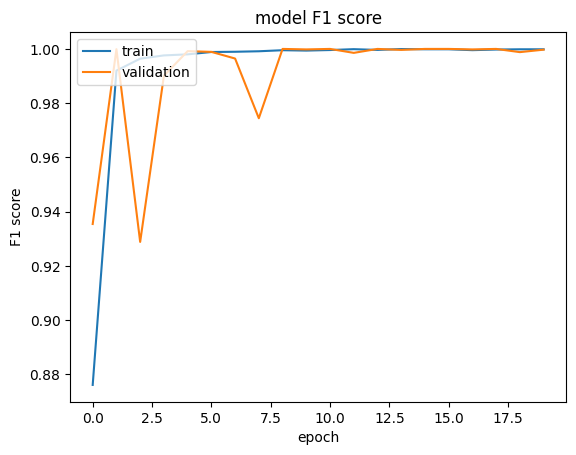

In [13]:
import matplotlib.pyplot as plt
plt.plot(history.history['f1_score'])
plt.plot(history.history['val_f1_score'])
plt.title('model F1 score')
plt.ylabel('F1 score')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

In [14]:
# Evaluate the model on test data
test_loss, test_f1_score = model.evaluate(x_test, y_test, verbose=0)

print("F1 Score on Test Data:", test_f1_score)

F1 Score on Test Data: 0.9472860097885132


## Diskusija rezultata

Vidimo da su se performanse CNN modela značajno bolje od performansi potpuno povezane neuronske mreže. Tačnost na trening skupu je veoma visoka, a unapredila se i tačnost na validacionom skupu.